<a href="https://colab.research.google.com/github/tutorbosun/hydraulics-python/blob/main/02_Pump_System_Duty_Point.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Duty point: 69.5 m3/h at 29.4 m


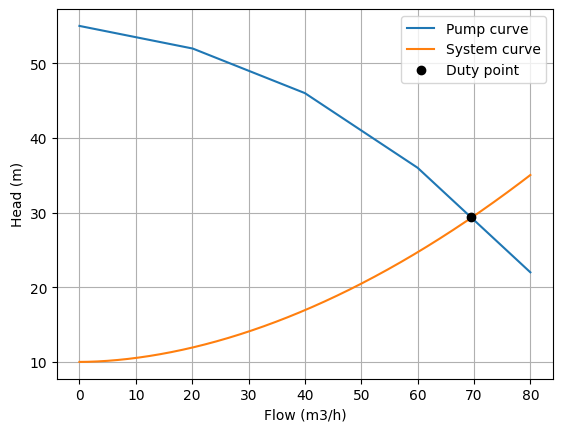

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def hazen_williams_headloss(L, d, Q, C):
  return 10.67 * L * Q**1.852 / (C**1.852 * d**4.87)

# Illustrative pump curve (replace with datasheet values later)
Q_pump = np.array([0, 20, 40, 60, 80])  # m3/h
H_pump = np.array([55, 52, 46, 36, 22])  # m

# System: 10m static head + 300 m of 100 mm pipe, C = 130
Q = np.linspace(0, 80, 801)  #m3/h
H_system = 10 + hazen_williams_headloss(300, 0.1, Q / 3600, 130)
H_pump_interp = np.interp(Q, Q_pump, H_pump)

# Duty point: where the pump curve minus the system curve changes sign
diff = H_pump_interp - H_system
i = np.where(np.diff(np.sign(diff)) != 0)[0][0]
print("Duty point:", round(Q[i], 1), "m3/h at", round(H_pump_interp[i], 1), "m")

plt.plot(Q, H_pump_interp, label="Pump curve")
plt.plot(Q, H_system, label="System curve")
plt.plot(Q[i], H_pump_interp[i], "ko", label="Duty point")
plt.xlabel("Flow (m3/h)"); plt.ylabel("Head (m)")
plt.legend(); plt.grid(True)
plt.savefig("duty_point.png", dpi=150)
plt.show()

